# E2 — Channel Scalability

## 1. Mục tiêu

Thí nghiệm đánh giá khả năng mở rộng của DeepKoopFormer khi số lượng biến của chuỗi thời gian đa biến tăng lên.

Các khía cạnh được khảo sát:

- **Độ chính xác:** Sự thay đổi MSE và MAE khi số lượng channels tăng.
- **Chi phí tính toán:** Thời gian huấn luyện và bộ nhớ GPU sử dụng.
- **Độ phức tạp mô hình:** Sự thay đổi số lượng tham số theo số channels.
- **So sánh kiến trúc:** Khả năng mở rộng của KoopPatchTST_Full so với PatchTST.

## 2. Thiết kế thực nghiệm

**Dataset:** Electricity, sử dụng dữ liệu đã chuẩn bị và kiểm chứng trong Ablation Study.

**Số channels:** 2, 4 và 6, lần lượt lấy các biến đầu tiên trong cùng bộ dữ liệu.

**Mô hình:**
- PatchTST
- KoopPatchTST_Full

**Cấu hình huấn luyện:**

| Tham số | Giá trị |
|---|---|
| Training timestamps | 2800 |
| Testing timestamps | 700 |
| Patch Length | 120 |
| Forecast Horizon | 8 |
| Epochs | 4000 |
| Learning Rate | 0.0003 |
| Optimizer | Adam |
| Seed | 7 |

Tổng cộng: **3 channel configurations × 2 models = 6 lượt huấn luyện**.

## 3. Phương pháp thực hiện

1. Sử dụng cùng một khoảng thời gian Train/Test của Electricity.
2. Tạo ba phiên bản dữ liệu với 2, 4 và 6 channels.
3. Chuẩn hóa Min-Max Scaling bằng thống kê của Train.
4. Tạo sliding windows với cùng Patch Length và Horizon.
5. Khởi tạo và huấn luyện lại từng mô hình với cùng siêu tham số.
6. Ghi nhận Test MSE, MAE, thời gian huấn luyện, peak GPU memory và số tham số.
7. Đánh giá độ chính xác trên cả toàn bộ channels và hai channels chung để đảm bảo tính so sánh.

## 4. Kết quả đầu ra

- 6 file `.pt` chứa kết quả từng cấu hình.
- Các checkpoint hỗ trợ Resume.
- `metrics.csv` chứa kết quả Train/Test.
- Biểu đồ về độ chính xác, thời gian huấn luyện, bộ nhớ GPU và số tham số theo số channels.

## 5. Ý nghĩa

Thực nghiệm khảo sát cách các kiến trúc PatchTST và DeepKoopFormer phản ứng khi số lượng biến tăng, qua đó đánh giá sự đánh đổi giữa độ chính xác và chi phí tính toán.

Đây là thí nghiệm mở rộng do nhóm thiết kế, không phải kết quả trực tiếp được công bố trong bài báo gốc.

E2 CHANNEL SCALABILITY: ENVIRONMENT SETUP

In [3]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import torch

# 1. Reproducibility
SEED = 7

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 2. Locate project root
PROJECT_ROOT = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (
            p / "experiments" / "05_ablation"
            / "02_ablation_model.ipynb"
        ).is_file()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot locate project root")

# 3. Directories
ABLATION_DIR = PROJECT_ROOT / "experiments" / "05_ablation"
SCALABILITY_DIR = PROJECT_ROOT / "experiments" / "06_scalability"

DATA_DIR = ABLATION_DIR / "data"
MODEL_NOTEBOOK = ABLATION_DIR / "02_ablation_model.ipynb"
DATA_PATH = DATA_DIR / "electricity_ablation.pt"

RESULTS_DIR = SCALABILITY_DIR / "results" / "e2_channel_scaling"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# 4. Experimental configuration
DATASET_NAME = "Electricity"

CHANNEL_COUNTS = [2, 4, 5]

MODEL_NAMES = [
    "PatchTST",
    "KoopPatchTST_Full"
]

PATCH_LEN = 120
HORIZON = 8
EPOCHS = 4000
LEARNING_RATE = 3e-4

# 5. Validate required files
assert MODEL_NOTEBOOK.is_file()
assert DATA_PATH.is_file()

# 6. Summary
print("=== E2: CHANNEL SCALABILITY ===")

print("Project:", PROJECT_ROOT)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nDataset:", DATASET_NAME)
print("Channel counts:", CHANNEL_COUNTS)
print("Models:", MODEL_NAMES)

print("\nPatch length:", PATCH_LEN)
print("Horizon:", HORIZON)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Seed:", SEED)

total = len(CHANNEL_COUNTS) * len(MODEL_NAMES)

print("\nTotal configurations:", total)
print("Results directory:", RESULTS_DIR)
print("\nENVIRONMENT SETUP PASSED!")


=== E2: CHANNEL SCALABILITY ===
Project: c:\Users\Win 11 New\Desktop\pa gk
Device: cuda
GPU: Quadro T1000

Dataset: Electricity
Channel counts: [2, 4, 5]
Models: ['PatchTST', 'KoopPatchTST_Full']

Patch length: 120
Horizon: 8
Epochs: 4000
Learning rate: 0.0003
Seed: 7

Total configurations: 6
Results directory: c:\Users\Win 11 New\Desktop\pa gk\experiments\06_scalability\results\e2_channel_scaling

ENVIRONMENT SETUP PASSED!


LOAD AND PREPARE CHANNEL DATASETS

In [5]:
# 1. Load original Electricity dataset
bundle = torch.load(
    DATA_PATH,
    map_location="cpu",
    weights_only=True
)

raw = bundle["raw"].detach().cpu().numpy()

original_train = bundle["train"]
original_test = bundle["test"]

# 2. Preserve original Train/Test split
split_idx = len(original_train)

raw_train = raw[:split_idx]
raw_test = raw[split_idx:]

# 3. Validate original data
assert raw.shape == (3500, 6)
assert raw_train.shape == (2800, 6)
assert raw_test.shape == (700, 6)

assert np.isfinite(raw).all()

# 4. Create channel configurations
E2_DATASETS = {}
summary = []

for n_channels in CHANNEL_COUNTS:

    # Select first N channels
    train_subset = raw_train[:, :n_channels].copy()
    test_subset = raw_test[:, :n_channels].copy()

    # Validate shapes
    assert train_subset.shape == (2800, n_channels)
    assert test_subset.shape == (700, n_channels)

    assert np.isfinite(train_subset).all()
    assert np.isfinite(test_subset).all()

    # Save in memory
    E2_DATASETS[n_channels] = {
        "raw_train": train_subset,
        "raw_test": test_subset,
        "channels": n_channels,
        "channel_indices": list(range(n_channels))
    }

    summary.append({
        "Channels": n_channels,
        "Train Shape": str(train_subset.shape),
        "Test Shape": str(test_subset.shape),
        "Status": "PASSED"
    })

# 5. Verify that the first two channels are identical
# across all configurations
for n_channels in CHANNEL_COUNTS:

    np.testing.assert_array_equal(
        E2_DATASETS[n_channels]["raw_train"][:, :2],
        E2_DATASETS[2]["raw_train"]
    )

    np.testing.assert_array_equal(
        E2_DATASETS[n_channels]["raw_test"][:, :2],
        E2_DATASETS[2]["raw_test"]
    )

# 6. Display summary
channel_df = pd.DataFrame(summary)

print("=== E2 CHANNEL DATASETS ===")
display(channel_df)

print("\nTotal configurations:", len(E2_DATASETS))
print("Train/Test split preserved.")
print("Common channels verified.")
print("\nCHANNEL DATA PREPARATION PASSED!")


=== E2 CHANNEL DATASETS ===


,Channels,Train Shape,Test Shape,Status
0,2,"(2800, 2)","(700, 2)",PASSED
1,4,"(2800, 4)","(700, 4)",PASSED
2,5,"(2800, 5)","(700, 5)",PASSED



Total configurations: 3
Train/Test split preserved.
Common channels verified.

CHANNEL DATA PREPARATION PASSED!


MIN-MAX SCALING

In [7]:
from sklearn.preprocessing import MinMaxScaler

E2_SCALED = {}
summary = []

for n_channels, data in E2_DATASETS.items():

    # 1. Original Train/Test
    raw_train = data["raw_train"]
    raw_test = data["raw_test"]

    # 2. Fit scaler on Train only
    scaler = MinMaxScaler(feature_range=(0, 1))

    train_scaled = scaler.fit_transform(
        raw_train
    ).astype(np.float32)

    test_scaled = scaler.transform(
        raw_test
    ).astype(np.float32)

    # 3. Validate dimensions and values
    assert train_scaled.shape == (2800, n_channels)
    assert test_scaled.shape == (700, n_channels)

    assert np.isfinite(train_scaled).all()
    assert np.isfinite(test_scaled).all()

    # 4. Compare with original Ablation data
    np.testing.assert_allclose(
        train_scaled,
        original_train.numpy()[:, :n_channels],
        rtol=1e-5,
        atol=1e-6
    )

    np.testing.assert_allclose(
        test_scaled,
        original_test.numpy()[:, :n_channels],
        rtol=1e-5,
        atol=1e-6
    )

    # 5. Store processed data
    E2_SCALED[n_channels] = {
        "train": train_scaled,
        "test": test_scaled,
        "scaler": scaler,
        "channels": n_channels,
        "channel_indices": data["channel_indices"]
    }

    summary.append({
        "Channels": n_channels,
        "Train Shape": str(train_scaled.shape),
        "Test Shape": str(test_scaled.shape),
        "Train Min": round(float(train_scaled.min()), 4),
        "Train Max": round(float(train_scaled.max()), 4),
        "Status": "PASSED"
    })

# 6. Summary
scaling_df = pd.DataFrame(summary)

print("=== E2 MIN-MAX SCALING ===")
display(scaling_df)

print("\nTotal configurations:", len(E2_SCALED))
print("All configurations matched Ablation data.")
print("MIN-MAX SCALING PASSED!")


=== E2 MIN-MAX SCALING ===


,Channels,Train Shape,Test Shape,Train Min,Train Max,Status
0,2,"(2800, 2)","(700, 2)",0.0,1.0,PASSED
1,4,"(2800, 4)","(700, 4)",0.0,1.0,PASSED
2,5,"(2800, 5)","(700, 5)",0.0,1.0,PASSED



Total configurations: 3
All configurations matched Ablation data.
MIN-MAX SCALING PASSED!


CREATE SLIDING WINDOWS

In [8]:
# 1. Sliding-window function
def create_windows(data, patch_len, horizon):

    X, Y = [], []

    # Same convention as Ablation Study
    n_windows = len(data) - patch_len - horizon

    for i in range(n_windows):

        # Input: 120 timestamps
        X.append(
            data[i:i + patch_len]
        )

        # Target: next 8 timestamps, feature-major
        Y.append(
            data[i + patch_len:i + patch_len + horizon]
            .T.reshape(-1)
        )

    return (
        torch.tensor(np.stack(X), dtype=torch.float32),
        torch.tensor(np.stack(Y), dtype=torch.float32)
    )


# 2. Create windows for each channel configuration
E2_WINDOWS = {}
summary = []

for n_channels, data in E2_SCALED.items():

    X_train, Y_train = create_windows(
        data["train"], PATCH_LEN, HORIZON
    )

    X_test, Y_test = create_windows(
        data["test"], PATCH_LEN, HORIZON
    )

    # 3. Validate shapes
    assert X_train.shape == (
        2800 - PATCH_LEN - HORIZON,
        PATCH_LEN,
        n_channels
    )

    assert Y_train.shape == (
        len(X_train),
        n_channels * HORIZON
    )

    assert X_test.shape == (
        700 - PATCH_LEN - HORIZON,
        PATCH_LEN,
        n_channels
    )

    assert Y_test.shape == (
        len(X_test),
        n_channels * HORIZON
    )

    # 4. Save in memory
    E2_WINDOWS[n_channels] = {
        "X_train": X_train,
        "Y_train": Y_train,
        "X_test": X_test,
        "Y_test": Y_test
    }

    summary.append({
        "Channels": n_channels,
        "Train Windows": len(X_train),
        "Test Windows": len(X_test),
        "X_train Shape": str(tuple(X_train.shape)),
        "Y_train Shape": str(tuple(Y_train.shape)),
        "Status": "PASSED"
    })


# 5. Display results
windows_df = pd.DataFrame(summary)

print("=== E2 SLIDING WINDOWS ===")
display(windows_df)

print("\nTotal configurations:", len(E2_WINDOWS))
print("SLIDING WINDOWS PASSED!")


=== E2 SLIDING WINDOWS ===


,Channels,Train Windows,Test Windows,X_train Shape,Y_train Shape,Status
0,2,2672,572,"(2672, 120, 2)","(2672, 16)",PASSED
1,4,2672,572,"(2672, 120, 4)","(2672, 32)",PASSED
2,5,2672,572,"(2672, 120, 5)","(2672, 40)",PASSED



Total configurations: 3
SLIDING WINDOWS PASSED!


LOAD AND VALIDATE MODELS

In [ ]:
import sys

# 1. Import model definitions from Ablation
sys.path.insert(0, str(ABLATION_DIR))
import ast
import json
import math
import torch.nn as nn

MODEL_DEFINITIONS = {
    "_orth",
    "StrictStableKoopmanOperator",
    "LinearLatentPropagator",
    "SinCosPosEnc",
    "PatchEmbed1D",
    "PatchTST_Backbone",
    "PatchTSTBaseline",
    "PatchTST_UnconstrainedLatent",
    "Koopformer_PatchTST",
    "SimpleLSTMForecaster",
    "DLinearForecaster",
    "create_ablation_model",
}


def load_model_notebook(path):
    """Load model definitions without executing notebook cells."""

    with open(path, encoding="utf-8") as f:
        notebook = json.load(f)

    definitions = []
    found = set()

    for cell in notebook["cells"]:
        if cell["cell_type"] != "code":
            continue

        source = cell["source"]
        source = (
            "".join(source)
            if isinstance(source, list)
            else source
        )

        if not source.strip():
            continue

        tree = ast.parse(source)

        for node in tree.body:
            if isinstance(node, (ast.ClassDef, ast.FunctionDef)):
                if node.name in MODEL_DEFINITIONS:
                    if node.name in found:
                        raise ValueError(
                            f"Duplicate definition: {node.name}"
                        )
                    definitions.append(node)
                    found.add(node.name)

    missing = MODEL_DEFINITIONS - found
    if missing:
        raise RuntimeError(
            f"Missing model definitions: {sorted(missing)}"
        )

    namespace = {
        "__name__": __name__,
        "torch": torch,
        "nn": nn,
        "np": np,
        "math": math,
        "D_MODEL": 96,
        "D_LATENT": 96,
        "LSTM_HIDDEN_DIM": 96,
        "LSTM_NUM_LAYERS": 2,
        "LYAP_WEIGHT": 0.1,
        "RHO_MAX": 0.99,
        "MODEL_VARIANTS": [
            "DLinear",
            "LSTM",
            "PatchTST",
            "PatchTST+LinearLatent",
            "KoopPatchTST_NoLyap",
            "KoopPatchTST_Full",
        ],
    }

    module = ast.Module(
        body=definitions,
        type_ignores=[]
    )
    ast.fix_missing_locations(module)

    exec(
        compile(module, str(path), "exec"),
        namespace
    )

    return namespace

model_definitions = load_model_notebook(MODEL_NOTEBOOK)

create_ablation_model = model_definitions[
    "create_ablation_model"
]

# 2. Validate models for each channel configuration
results = []

for n_channels in CHANNEL_COUNTS:

    dummy_input = torch.zeros(
        2, PATCH_LEN, n_channels,
        device=DEVICE
    )

    for model_name in MODEL_NAMES:

        # Initialize model
        model, koop_attr, lyap_weight = (
            create_ablation_model(
                model_name=model_name,
                input_dim=n_channels,
                patch_len=PATCH_LEN,
                horizon=HORIZON
            )
        )

        model = model.to(DEVICE)
        model.eval()

        # 3. Forward pass
        with torch.no_grad():
            prediction = model(dummy_input)

        assert prediction.shape == (
            2, n_channels * HORIZON
        )

        assert torch.isfinite(prediction).all()

        # 4. Count trainable parameters
        n_params = sum(
            p.numel()
            for p in model.parameters()
            if p.requires_grad
        )

        results.append({
            "Channels": n_channels,
            "Model": model_name,
            "Parameters": n_params,
            "Input Shape": str(tuple(dummy_input.shape)),
            "Output Shape": str(tuple(prediction.shape)),
            "Lyap Weight": lyap_weight,
            "Status": "PASSED"
        })

        del model

# 5. Summary
model_df = pd.DataFrame(results)

print("=== E2 MODEL VALIDATION ===")
display(model_df)

assert len(model_df) == 6
assert (model_df["Status"] == "PASSED").all()

print("\nTotal models validated:", len(model_df))
print("MODEL VALIDATION PASSED!")


=== E2 MODEL VALIDATION ===


,Channels,Model,Parameters,Input Shape,Output Shape,Lyap Weight,Status
0,2,PatchTST,193552,"(2, 120, 2)","(2, 16)",0.0,PASSED
1,2,KoopPatchTST_Full,212080,"(2, 120, 2)","(2, 16)",0.1,PASSED
2,4,PatchTST,218144,"(2, 120, 4)","(2, 32)",0.0,PASSED
3,4,KoopPatchTST_Full,236672,"(2, 120, 4)","(2, 32)",0.1,PASSED
4,5,PatchTST,230440,"(2, 120, 5)","(2, 40)",0.0,PASSED
5,5,KoopPatchTST_Full,248968,"(2, 120, 5)","(2, 40)",0.1,PASSED



Total models validated: 6
MODEL VALIDATION PASSED!


E2 FULL TRAINING + CHECKPOINT + METRICS

In [ ]:
import time
import gc
import hashlib
import torch.optim as optim


# 1. Reproducibility
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# 2. Prediction Loss + Lyapunov Regularization
def loss_parts(model, X, Y, lyap_weight):
    pred, z, z_next = model(X, return_latents=True)

    mse = F.mse_loss(pred, Y)

    if lyap_weight:
        lyap = torch.relu(
            z_next.square().sum(1)
            - z.square().sum(1)
        ).mean()
    else:
        lyap = mse.new_zeros(())

    return mse + lyap_weight * lyap, mse, lyap

# 3. Save Random Number Generator States
def snapshot_rng():
    n = np.random.get_state()

    return {
        "python": random.getstate(),
        "torch": torch.get_rng_state(),
        "cuda": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available()
            else []
        ),
        "numpy": {
            "name": n[0],
            "keys": n[1].tolist(),
            "pos": int(n[2]),
            "has_gauss": int(n[3]),
            "cached": float(n[4])
        }
    }

# 4. Restore Random Number Generator States
def restore_rng(state):
    random.setstate(state["python"])
    torch.set_rng_state(state["torch"])

    if torch.cuda.is_available() and state.get("cuda"):
        if len(state["cuda"]) != torch.cuda.device_count():
            print(
                "WARNING: GPU count changed; "
                "CUDA RNG exact restoration unavailable",
                flush=True
            )
        else:
            torch.cuda.set_rng_state_all(state["cuda"])

    n = state["numpy"]

    np.random.set_state((
        n["name"],
        np.asarray(n["keys"], dtype=np.uint32),
        n["pos"],
        n["has_gauss"],
        n["cached"]
    ))

# 5. Load Saved PyTorch Artifacts

def safe_load(path):
    try:
        return torch.load(
            path,
            map_location="cpu",
            weights_only=True
        )
    except TypeError:
        return torch.load(
            path,
            map_location="cpu"
        )

# 6. Atomic Checkpoint Saving
def atomic_torch_save(obj, path):
    tmp = path.with_name(
        path.name + f".{os.getpid()}.tmp"
    )

    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    torch.save(obj, tmp)
    os.replace(tmp, path)


# 7. Batched Model Prediction
def predict_cpu_tensor(model, X, device, batch_size):
    model.eval()
    chunks = []

    with torch.inference_mode():
        for start in range(0, len(X), batch_size):
            xb = X[start:start + batch_size].to(device)

            chunks.append(
                model(xb).detach().to("cpu").clone()
            )

    return torch.cat(chunks, dim=0)

CHECKPOINT_EVERY = 250

CKPT_DIR = RESULTS_DIR / "checkpoints"
MODEL_DIR = RESULTS_DIR / "models"
CSV_PATH = RESULTS_DIR / "metrics.csv"

CKPT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_SHA = hashlib.sha256(
    MODEL_NOTEBOOK.read_bytes()
).hexdigest()


# 1. EVALUATION

def evaluate_split(model, X, Y, scaler, channels):

    prediction = predict_cpu_tensor(
        model, X, DEVICE, 256
    ).numpy().astype(np.float64)

    target = Y.numpy().astype(np.float64)

    # Shape: (samples, channels * horizon)
    # Convert to (samples, horizon, channels)
    def reshape_output(values):
        return values.reshape(
            -1, channels, HORIZON
        ).transpose(0, 2, 1)

    pred_3d = reshape_output(prediction)
    true_3d = reshape_output(target)

    # Convert predictions to original units
    pred_raw = scaler.inverse_transform(
        pred_3d.reshape(-1, channels)
    ).reshape(-1, HORIZON, channels)

    true_raw = scaler.inverse_transform(
        true_3d.reshape(-1, channels)
    ).reshape(-1, HORIZON, channels)

    # All-channel errors
    diff = pred_raw - true_raw
    scaled_diff = prediction - target

    # Common first 2 channels
    diff_common = diff[:, :, :2]

    return {
        "MSE": float(np.mean(diff ** 2)),
        "MAE": float(np.mean(np.abs(diff))),

        "MSE_2ch": float(np.mean(diff_common ** 2)),
        "MAE_2ch": float(np.mean(np.abs(diff_common))),

        "MSE_Scaled": float(
            np.mean(scaled_diff ** 2)
        ),
        "MAE_Scaled": float(
            np.mean(np.abs(scaled_diff))
        )
    }


# 2. UPDATE METRICS.CSV

metric_rows = {}

def update_metrics_csv(artifact, slug):

    cfg = artifact["config"]

    for split in ("Train", "Test"):

        metric_rows[(slug, split)] = {
            "Dataset": cfg["dataset"],
            "Channels": cfg["channels"],
            "Model": cfg["model"],
            "Split": split,

            "Train_Windows": artifact["train_windows"],
            "Test_Windows": artifact["test_windows"],
            "Parameters": artifact["parameters"],
            "Epochs": cfg["epochs"],

            **artifact["metrics"][split],

            "Train_Seconds": artifact["train_seconds"],
            "Seconds_Per_Epoch": (
                artifact["train_seconds"] / cfg["epochs"]
            ),
            "Peak_GPU_MB": artifact["peak_gpu_mb"],
            "Seed": cfg["seed"]
        }

    df = pd.DataFrame(metric_rows.values())

    df = df.sort_values(
        ["Channels", "Model", "Split"]
    )

    temp_path = CSV_PATH.with_suffix(".csv.tmp")
    df.to_csv(temp_path, index=False)
    temp_path.replace(CSV_PATH)


# Recover metrics from completed .pt files
for path in sorted(MODEL_DIR.glob("*.pt")):
    artifact = safe_load(path)
    update_metrics_csv(artifact, path.stem)


# 3. FULL TRAINING — 6 CONFIGURATIONS

run_index = 0
total_runs = len(CHANNEL_COUNTS) * len(MODEL_NAMES)

for channels in CHANNEL_COUNTS:

    data = E2_WINDOWS[channels]
    scaled = E2_SCALED[channels]
    scaler = scaled["scaler"]

    data_sha = hashlib.sha256(
        scaled["train"].tobytes()
        + scaled["test"].tobytes()
    ).hexdigest()

    for model_name in MODEL_NAMES:

        run_index += 1

        slug = (
            f"electricity_"
            f"{model_name.lower()}_"
            f"c{channels}"
        )

        pt_path = MODEL_DIR / f"{slug}.pt"
        ckpt_path = CKPT_DIR / slug / "latest.pt"

        config = {
            "dataset": DATASET_NAME,
            "channels": channels,
            "model": model_name,
            "patch_len": PATCH_LEN,
            "horizon": HORIZON,
            "epochs": EPOCHS,
            "lr": LEARNING_RATE,
            "seed": SEED,
            "data_sha256": data_sha,
            "model_sha256": MODEL_SHA,
            "device": DEVICE.type
        }

        print(
            f"\n[{run_index}/{total_runs}] "
            f"Electricity | {model_name} | "
            f"Channels={channels}",
            flush=True
        )

        # Skip completed model
        if pt_path.exists():

            saved = safe_load(pt_path)

            if saved["config"] != config:
                raise ValueError(
                    f"Config mismatch: {pt_path}"
                )

            update_metrics_csv(saved, slug)
            print("SKIP: already completed")
            continue

        # Initialize reproducibly
        seed_everything(SEED)

        model, koop_attr, lyap_weight = (
            create_ablation_model(
                model_name=model_name,
                input_dim=channels,
                patch_len=PATCH_LEN,
                horizon=HORIZON
            )
        )

        model = model.to(DEVICE)

        optimizer = optim.Adam(
            model.parameters(),
            lr=LEARNING_RATE
        )

        X = data["X_train"].to(DEVICE)
        Y = data["Y_train"].to(DEVICE)

        start_epoch = 0
        old_seconds = 0.0
        old_peak = 0.0

        # Resume if interrupted
        if ckpt_path.exists():

            checkpoint = safe_load(ckpt_path)

            if checkpoint["config"] != config:
                raise ValueError(
                    f"Checkpoint mismatch: {ckpt_path}"
                )

            model.load_state_dict(
                checkpoint["model_state_dict"]
            )

            optimizer.load_state_dict(
                checkpoint["optimizer_state_dict"]
            )

            for state in optimizer.state.values():
                for key, value in state.items():
                    if torch.is_tensor(value):
                        state[key] = value.to(DEVICE)

            start_epoch = checkpoint["epoch"]
            old_seconds = checkpoint["train_seconds"]
            old_peak = checkpoint["peak_gpu_mb"]

            restore_rng(checkpoint["rng"])

            print(
                f"RESUME: epoch {start_epoch}/{EPOCHS}",
                flush=True
            )

        # Start measurement
        if DEVICE.type == "cuda":
            torch.cuda.reset_peak_memory_stats()
            torch.cuda.synchronize()

        start_time = time.perf_counter()

        train_seconds = old_seconds
        peak_mb = old_peak

        # Train 4000 epochs
        for epoch in range(start_epoch, EPOCHS):

            model.train()
            optimizer.zero_grad()

            # Same loss as Ablation Study
            loss, mse, lyap = loss_parts(
                model, X, Y, lyap_weight
            )

            if not torch.isfinite(loss).item():
                raise FloatingPointError(
                    f"Non-finite loss at epoch {epoch + 1}"
                )

            loss.backward()
            optimizer.step()

            # Progress every 500 epochs
            if (epoch + 1) % 500 == 0:

                print(
                    f"  Epoch {epoch + 1}/{EPOCHS} | "
                    f"MSE={mse.item():.6f} | "
                    f"Loss={loss.item():.6f}",
                    flush=True
                )

            # Checkpoint every 250 epochs
            if (
                (epoch + 1) % CHECKPOINT_EVERY == 0
                or epoch + 1 == EPOCHS
            ):

                if DEVICE.type == "cuda":

                    torch.cuda.synchronize()

                    peak_mb = max(
                        old_peak,
                        torch.cuda.max_memory_allocated()
                        / 1024**2
                    )

                train_seconds = (
                    old_seconds
                    + time.perf_counter() - start_time
                )

                atomic_torch_save(
                    {
                        "config": config,
                        "epoch": epoch + 1,
                        "model_state_dict": model.state_dict(),
                        "optimizer_state_dict": optimizer.state_dict(),
                        "train_seconds": train_seconds,
                        "peak_gpu_mb": peak_mb,
                        "rng": snapshot_rng()
                    },
                    ckpt_path
                )

        # Evaluate Train and Test
        train_metrics = evaluate_split(
            model,
            data["X_train"],
            data["Y_train"],
            scaler,
            channels
        )

        test_metrics = evaluate_split(
            model,
            data["X_test"],
            data["Y_test"],
            scaler,
            channels
        )

        # Final model artifact
        artifact = {
            "config": config,

            "model_state_dict": {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            },

            "scaler": {
                "scale": scaler.scale_.tolist(),
                "min": scaler.min_.tolist()
            },

            "metrics": {
                "Train": train_metrics,
                "Test": test_metrics
            },

            "channel_indices": scaled["channel_indices"],

            "train_windows": len(data["X_train"]),
            "test_windows": len(data["X_test"]),

            "parameters": sum(
                p.numel()
                for p in model.parameters()
                if p.requires_grad
            ),

            "train_seconds": train_seconds,
            "peak_gpu_mb": peak_mb
        }

        # Save .pt and immediately update CSV
        atomic_torch_save(artifact, pt_path)
        update_metrics_csv(artifact, slug)

        print(
            f"DONE | "
            f"Test MSE={test_metrics['MSE']:.6g} | "
            f"MSE_2ch={test_metrics['MSE_2ch']:.6g} | "
            f"Time={train_seconds:.1f}s | "
            f"Peak GPU={peak_mb:.1f} MB",
            flush=True
        )

        # Release memory
        del model, optimizer, X, Y
        gc.collect()

        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()


print(
    f"\nFINISHED: {len(metric_rows)//2}/6 models; "
    f"{len(metric_rows)}/12 CSV rows"
)


[1/6] Electricity | PatchTST | Channels=2
  Epoch 500/4000 | MSE=0.021243 | Loss=0.021243
  Epoch 1000/4000 | MSE=0.013059 | Loss=0.013059
  Epoch 1500/4000 | MSE=0.009335 | Loss=0.009335
  Epoch 2000/4000 | MSE=0.007728 | Loss=0.007728
  Epoch 2500/4000 | MSE=0.006502 | Loss=0.006502
  Epoch 3000/4000 | MSE=0.005701 | Loss=0.005701
  Epoch 3500/4000 | MSE=0.004904 | Loss=0.004904
  Epoch 4000/4000 | MSE=0.004621 | Loss=0.004621
DONE | Test MSE=25879.2 | MSE_2ch=25879.2 | Time=116.3s | Peak GPU=106.7 MB

[2/6] Electricity | KoopPatchTST_Full | Channels=2
  Epoch 500/4000 | MSE=0.018327 | Loss=0.018327
  Epoch 1000/4000 | MSE=0.010143 | Loss=0.010143
  Epoch 1500/4000 | MSE=0.007562 | Loss=0.007562
  Epoch 2000/4000 | MSE=0.005994 | Loss=0.005994
  Epoch 2500/4000 | MSE=0.005092 | Loss=0.005092
  Epoch 3000/4000 | MSE=0.004337 | Loss=0.004337
  Epoch 3500/4000 | MSE=0.003955 | Loss=0.003955
  Epoch 4000/4000 | MSE=0.003537 | Loss=0.003537
DONE | Test MSE=18878.9 | MSE_2ch=18878.9 | Tim

VISUALIZE E2 CHANNEL SCALING

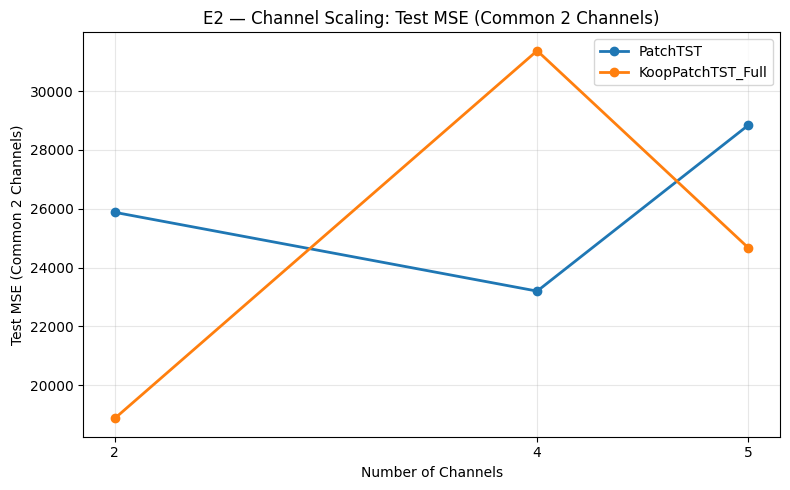

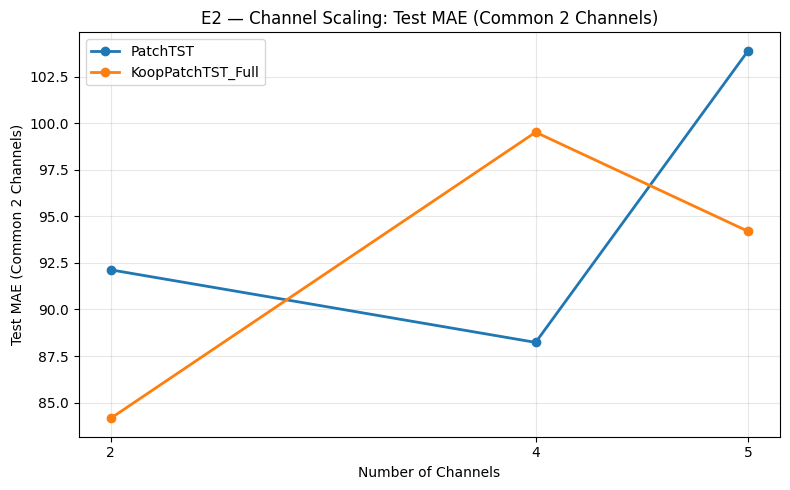

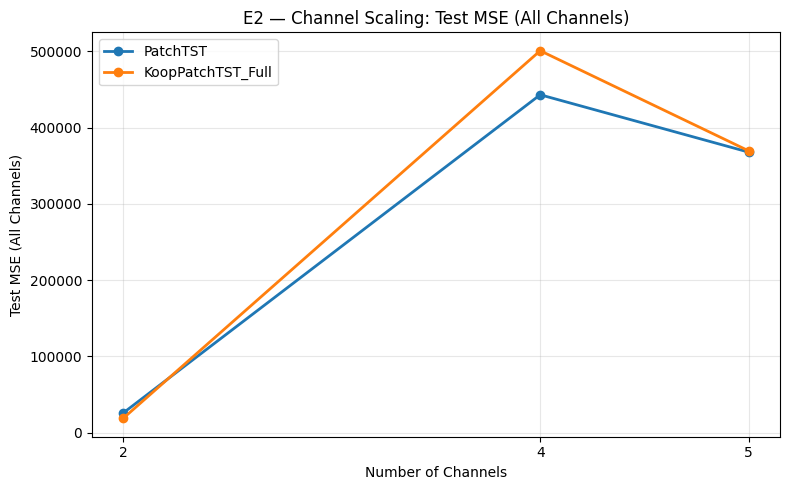

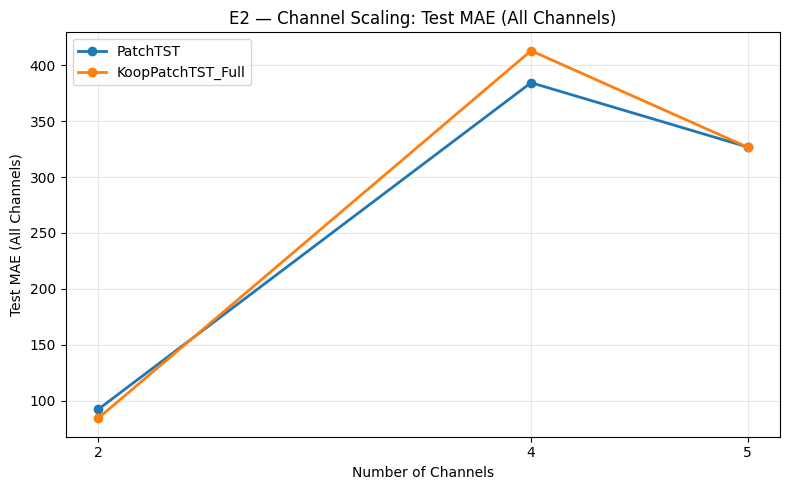

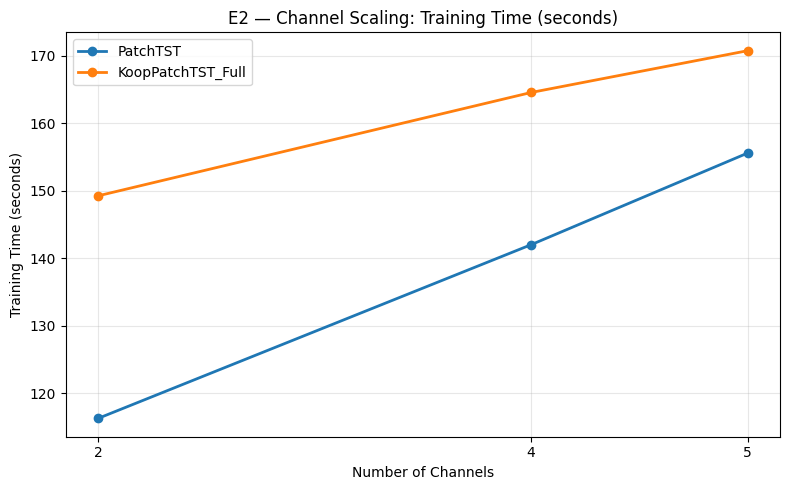

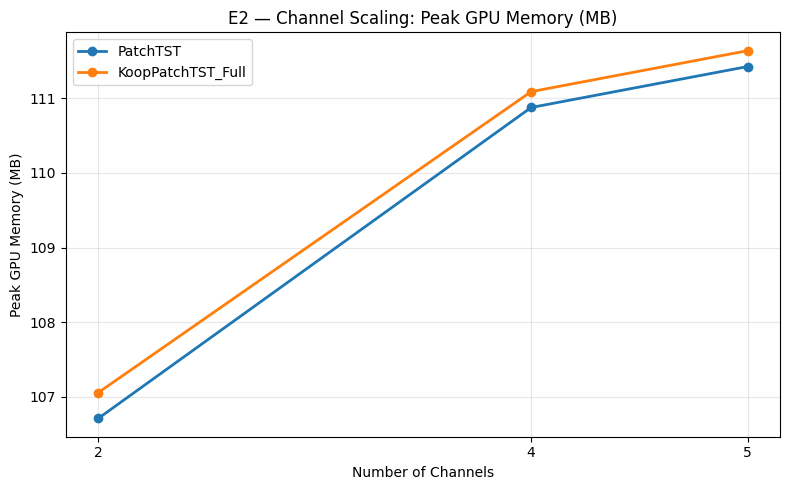

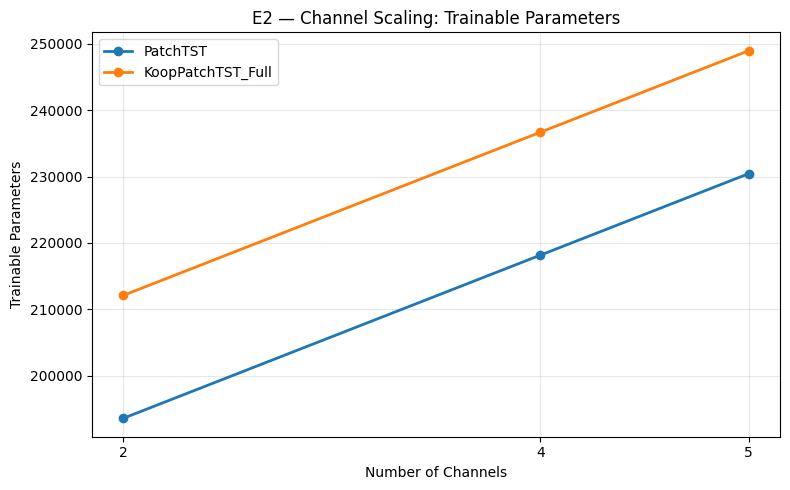


All 7 channel scaling figures saved!
Output: c:\Users\Win 11 New\Desktop\pa gk\experiments\06_scalability\results\e2_channel_scaling\figures


In [11]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Load results
df = pd.read_csv(RESULTS_DIR / "metrics.csv")
df = df[df["Split"] == "Test"].copy()

FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# 2. Metrics to visualize
METRICS = {
    "MSE_2ch": "Test MSE (Common 2 Channels)",
    "MAE_2ch": "Test MAE (Common 2 Channels)",
    "MSE": "Test MSE (All Channels)",
    "MAE": "Test MAE (All Channels)",
    "Train_Seconds": "Training Time (seconds)",
    "Peak_GPU_MB": "Peak GPU Memory (MB)",
    "Parameters": "Trainable Parameters"
}

# 3. Generate figures
for metric, ylabel in METRICS.items():

    plt.figure(figsize=(8, 5))

    for model_name in MODEL_NAMES:

        model_df = df[
            df["Model"] == model_name
        ].sort_values("Channels")

        plt.plot(
            model_df["Channels"],
            model_df[metric],
            marker="o",
            linewidth=2,
            label=model_name
        )

    plt.title(f"E2 — Channel Scaling: {ylabel}")
    plt.xlabel("Number of Channels")
    plt.ylabel(ylabel)

    plt.xticks(CHANNEL_COUNTS)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    # 4. Save figure
    filename = f"electricity_{metric.lower()}.png"

    plt.savefig(
        FIG_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

print("\nAll 7 channel scaling figures saved!")
print("Output:", FIG_DIR)
